# Tìm keyword liên hệ với rating thấp bằng TF-IDF + Logistic Regression

**Mục tiêu cuối:** tạo danh sách keyword ứng viên và giải thích đóng góp của chúng trong từng review. Nhãn rating được dùng để huấn luyện một nhiệm vụ trung gian: nhận diện review có `0 < rating ≤ 5`.

Notebook độc lập, không cần chạy notebook EDA trước. Phần đọc dữ liệu, chuẩn hóa, khóa lọc trùng 6 thành phần, loại rating 0 và loại comment 0 token được triển khai theo bản `eda._present.ipynb` đã đọc. Không sửa notebook EDA hay dữ liệu nguồn.

**Hai cách xem kết quả:**

| Phạm vi | Đại lượng | Câu hỏi |
|---|---|---|
| Toàn bộ mô hình | Hệ số cố định `w_j` | Cụm nào đẩy dự đoán về nhóm điểm thấp? |
| Một review | `x_j × w_j` | Trong review này, cụm nào đóng góp và đóng góp bao nhiêu? |

Trọng số được lưu cho từng feature trong từ vựng đã học. Feature không xuất hiện có TF-IDF bằng 0 và không đóng góp. Từ/cụm ngoài từ vựng bị bỏ qua. Mô hình không trực tiếp xuất một danh sách keyword: ta xây bước xếp hạng và kiểm tra sau huấn luyện.

**Cách chạy:** đặt notebook trong thư mục `notebooks`, kiểm tra `DATA_PATH` ở phần 1, rồi chọn **Restart Kernel and Run All**. Cần `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `joblib`, `IPython`; nếu thiếu, cài trong đúng môi trường Python của Jupyter. Các bảng và điểm số chỉ có sau khi chạy trên dữ liệu thật; notebook được giao không chứa kết quả mô hình giả định.


## 1. Cấu hình thí nghiệm

Đường dẫn mặc định lấy từ notebook EDA. Nếu thư mục `../data/processed` tồn tại thì ưu tiên đường dẫn tương đối để dễ chuyển máy.

- Nhãn `1`: `0 < rating ≤ 5`; nhãn `0`: `5 < rating ≤ 10`.
- TF-IDF dùng regex và n-gram 1–3 như EDA, giữ cả từ phủ định. Regex tách theo token, không phải bộ tách từ tiếng Việt; ví dụ “phục vụ” gồm hai token.
- `min_df=5` và `max_features=100000` giới hạn từ vựng, chỉ fit trên tập huấn luyện tương ứng. Feature hiếm hoặc ngoài giới hạn có thể bị loại.
- Thử `C ∈ {0.1, 1, 10}` trên validation; `C` nhỏ tương ứng regularization mạnh hơn. Dùng trọng số lớp `balanced`, ngưỡng dự đoán 0.5 cố định.
- Ngưỡng support 30, support thấp 10 và lift 2 chỉ dành cho **bảng keyword tham khảo**, không dùng để chọn feature trước khi chia dữ liệu.


In [1]:
from pathlib import Path
import hashlib
import json
import re
import unicodedata
import warnings
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.special import expit
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

WINDOWS_DATA_PATH = Path(r'D:\FPT\ADY291m\project\data\processed\18-10-2026.json')
RELATIVE_DATA_PATH = Path('../data/processed/18-10-2026.json')
DATA_PATH = RELATIVE_DATA_PATH if RELATIVE_DATA_PATH.is_file() else WINDOWS_DATA_PATH
OUTPUT_DIR = Path('outputs/logistic_keywords')

SEED = 42
LOW_RATING_THRESHOLD = 5.0
MAX_RATING = 10.0  # Dữ liệu Foody; không dùng nguyên ngưỡng này cho thang 1–5.
TOKEN_PATTERN = r'(?u)\b\w+\b'
NGRAM_RANGE = (1, 3)
MIN_DF = 5
MAX_FEATURES = 100_000
C_VALUES = (0.1, 1.0, 10.0)
MAX_ITER = 2000
CLASS_WEIGHT = 'balanced'
PREDICTION_THRESHOLD = 0.5
TEST_GROUP_SIZE = 0.20
VALID_GROUP_SIZE_OF_REMAINDER = 0.25
MIN_TOTAL_SUPPORT = 30
MIN_LOW_SUPPORT = 10
MIN_DISPLAY_LIFT = 2.0
TOP_N = 30
CONTEXT_SAMPLE_SIZE = 5

print('scikit-learn:', sklearn.__version__)
print('Dữ liệu:', DATA_PATH)


scikit-learn: 1.7.2
Dữ liệu: ..\data\processed\18-10-2026.json


## 2. Đọc dữ liệu nguồn

Đọc cùng JSON mà EDA đang dùng. Không lấy riêng nhóm điểm thấp: cần cả nhóm thấp và cao để mô hình học phân biệt. Kiểm tra đầy đủ cột của khóa lọc trùng; thiếu cột sẽ báo lỗi thay vì âm thầm đổi quy tắc.


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'Không tìm thấy {DATA_PATH}. Hãy sửa DATA_PATH ở phần 1 '
        'thành đường dẫn JSON thật trên máy đang chạy Jupyter.'
    )

raw = pd.read_json(
    DATA_PATH,
    dtype={'source_review_id': 'string', 'shop_id': 'string', 'user_pseudo_id': 'string'},
)
required_columns = {
    'rating', 'comment_text', 'source_platform', 'shop_id',
    'comment_datetime', 'device',
}
absent = required_columns - set(raw.columns)
if absent:
    raise ValueError(f'Dữ liệu thiếu cột theo quy tắc EDA 6 thành phần: {sorted(absent)}')

print(f'Tổng dòng nguồn: {len(raw):,}')
print('Các cột:', list(raw.columns))


Tổng dòng nguồn: 138,131
Các cột: ['review_id', 'source_review_id', 'shop_id', 'user_pseudo_id', 'rating', 'device', 'comment_datetime', 'comment_text', 'num_photos', 'source_platform', 'crawled_at', 'user_name', 'first_seen_at', 'shop_name', 'city', 'region', 'opening_hour', 'closing_hour', 'price_min', 'price_max', 'views', 'shop_review_count', 'shop_avg_rating', 'excellent_count', 'good_count', 'average_count', 'poor_count', 'location_score', 'price_score', 'quality_score', 'service_score', 'space_score', 'last_crawled_at', 'shop_url']


## 3. Tạo tập làm việc theo quy tắc EDA

Chuẩn hóa NFC, chữ thường và khoảng trắng. Khóa lọc trùng gồm nền tảng, quán, thời điểm, device, rating số và nội dung chuẩn hóa; chỉ loại khi **đủ tất cả thành phần khóa**. Dòng thiếu khóa vẫn giữ. Sau đó giữ rating hợp lệ, khác 0 và comment có ít nhất một token.

Các thao tác này theo quy tắc cố định, chưa học từ vựng/IDF hay chọn keyword. Nhãn được suy ra từ rating, không phải nhãn thủ công về ý chê. Một câu cùng nội dung có thể có nhiều rating và vẫn tồn tại trong dữ liệu sau lọc.


In [3]:
MISSING_VALUES = {'', 'unknown', 'none', 'null', 'nan', 'nat', '<na>', 'n/a'}
TOKEN_REGEX = re.compile(TOKEN_PATTERN)

def normalize_text(value):
    if pd.isna(value):
        return ''
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(value)).lower()).strip()

def prepare_working(source):
    frame = source.copy(deep=True).reset_index(drop=True)
    frame['_source_row'] = np.arange(len(frame))
    frame['rating_num'] = pd.to_numeric(frame['rating'], errors='coerce')
    frame['text_norm'] = frame['comment_text'].map(normalize_text)

    keys = pd.DataFrame(index=frame.index)
    for col in ['source_platform', 'shop_id', 'comment_datetime', 'device']:
        values = frame[col].astype('string').str.normalize('NFC').str.strip()
        if col == 'device':
            values = values.str.lower()
        keys[col] = values.mask(values.str.lower().isin(MISSING_VALUES))
    keys['rating_num'] = frame['rating_num']
    keys['text_norm'] = frame['text_norm'].replace('', pd.NA)
    complete_key = keys.notna().all(axis=1)
    duplicate_mask = complete_key & keys.duplicated(keep='first')
    clean = frame.loc[~duplicate_mask].copy()

    valid = clean['text_norm'].ne('') & clean['rating_num'].between(0, MAX_RATING)
    corpus = clean.loc[valid].copy()
    corpus['n_tokens'] = corpus['text_norm'].map(lambda text: len(TOKEN_REGEX.findall(text)))
    zero_rating = corpus['rating_num'].eq(0)
    zero_tokens = corpus['n_tokens'].eq(0)
    working = corpus.loc[~(zero_rating | zero_tokens)].copy().reset_index(drop=True)
    working['is_low'] = working['rating_num'].le(LOW_RATING_THRESHOLD).astype(np.int8)

    audit = pd.Series({
        'Dòng nguồn': len(frame),
        'Thiếu khóa lọc trùng, được giữ ở bước dedup': int((~complete_key).sum()),
        'Dòng trùng bị loại': int(duplicate_mask.sum()),
        'Dòng sau dedup': len(clean),
        'Dòng rỗng text hoặc rating không hợp lệ, sau dedup': int((~valid).sum()),
        'Rating 0 trong corpus hợp lệ': int(zero_rating.sum()),
        'Comment 0 token trong corpus hợp lệ': int(zero_tokens.sum()),
        'Đồng thời rating 0 và 0 token': int((zero_rating & zero_tokens).sum()),
        'Dòng cuối cùng': len(working),
    }, name='Số review')
    if working.empty or working['is_low'].nunique() != 2:
        raise ValueError('Cần dữ liệu sau lọc có đủ cả hai nhóm rating.')
    assert working['rating_num'].gt(0).all()
    assert working['n_tokens'].gt(0).all()
    assert not working['_source_row'].isin(frame.loc[duplicate_mask, '_source_row']).any()
    return working, audit

working, cleaning_audit = prepare_working(raw)
display(cleaning_audit.to_frame())
display(working.groupby('is_low').agg(
    n_reviews=('is_low', 'size'), n_unique_texts=('text_norm', 'nunique'),
))
print(f'Tỷ lệ điểm thấp sau lọc: {working["is_low"].mean():.2%}')


,Số review
Dòng nguồn,138131
"Thiếu khóa lọc trùng, được giữ ở bước dedup",0
Dòng trùng bị loại,5305
Dòng sau dedup,132826
"Dòng rỗng text hoặc rating không hợp lệ, sau dedup",0
Rating 0 trong corpus hợp lệ,40
Comment 0 token trong corpus hợp lệ,146
Đồng thời rating 0 và 0 token,0
Dòng cuối cùng,132640


,n_reviews,n_unique_texts
is_low,,
0,109496,105995
1,23144,20541


Tỷ lệ điểm thấp sau lọc: 17.45%


## 4. Tách train, validation và test theo nhóm nội dung

Tách test trước, rồi tách train/validation từ phần còn lại. Các review cùng `text_norm` luôn ở cùng một tập. Khoảng 60/20/20 là tỷ lệ **nhóm nội dung**, số review thực tế có thể khác. Seed cố định, không thử nhiều seed rồi chọn kết quả đẹp. Nếu tập nào thiếu lớp thì dừng để xem lại thiết kế chia dữ liệu.

Train dùng fit TF-IDF và hệ số. Validation chọn `C`. Sau đó fit lại trên train + validation; test chỉ dùng đánh giá cuối. Các ứng viên lift cũ được chọn từ toàn dataset không được dùng để lọc feature ở đây, vì có thể đã nhìn thấy test.

Chia theo nội dung chỉ ngăn nguyên câu chuẩn hóa lặp giữa các tập; chưa ngăn câu gần giống, cùng quán hoặc cùng thời điểm. Kết quả không chứng minh khả năng tổng quát sang quán mới.


,split,n_reviews,n_unique_texts,low_count,low_pct
0,train,79949,75672,14048,17.57
1,validation,26205,25225,4489,17.13
2,test,26486,25225,4607,17.39


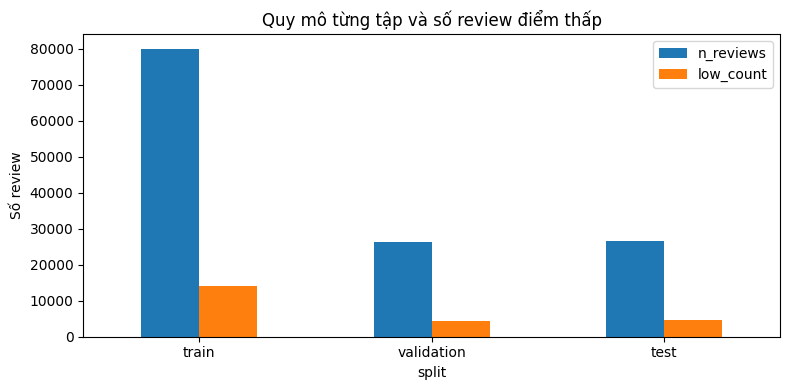

In [4]:
outer_split = GroupShuffleSplit(n_splits=1, test_size=TEST_GROUP_SIZE, random_state=SEED)
dev_pos, test_pos = next(outer_split.split(working, groups=working['text_norm']))
development = working.iloc[dev_pos].copy()
test = working.iloc[test_pos].copy()

inner_split = GroupShuffleSplit(
    n_splits=1, test_size=VALID_GROUP_SIZE_OF_REMAINDER, random_state=SEED + 1,
)
train_pos, valid_pos = next(inner_split.split(development, groups=development['text_norm']))
train = development.iloc[train_pos].copy()
validation = development.iloc[valid_pos].copy()

parts = {'train': train, 'validation': validation, 'test': test}
for name, part in parts.items():
    if part['is_low'].nunique() != 2:
        raise ValueError(f'{name} thiếu một lớp; cần xem lại cách chia và lượng dữ liệu.')
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(parts[a]['text_norm']).isdisjoint(parts[b]['text_norm'])
assert sum(len(part) for part in parts.values()) == len(working)

split_report = pd.DataFrame([
    {'split': name, 'n_reviews': len(part), 'n_unique_texts': part['text_norm'].nunique(),
     'low_count': int(part['is_low'].sum()), 'low_pct': part['is_low'].mean() * 100}
    for name, part in parts.items()
])
display(split_report.round(2))
split_report.plot.bar(x='split', y=['n_reviews', 'low_count'], rot=0, figsize=(8, 4))
plt.title('Quy mô từng tập và số review điểm thấp')
plt.ylabel('Số review')
plt.tight_layout()
plt.show()


## 5. Xây Pipeline và các chỉ số đánh giá

Pipeline nối `TfidfVectorizer` với Logistic Regression. Mỗi review là một hàng của ma trận thưa. Mỗi feature có một cột TF-IDF và một hệ số; không chuyển toàn bộ ma trận sang dense.

Với `y=1` là điểm thấp: `z = b + Σ(w_j x_j)` và `p_low = sigmoid(z)`. L2 làm co hệ số, thường không đặt chính xác tất cả feature yếu bằng 0; mô hình không tự chọn duy nhất một keyword.

Chọn `C` bằng **macro-F1 validation**. Báo cáo precision/recall/F1 nhóm thấp, accuracy, ROC-AUC và average precision (AP) để xem thêm. AP là average precision theo đường precision-recall, không gọi là diện tích hình thang. Với `class_weight='balanced'`, xác suất có thể chưa hiệu chỉnh tốt; không diễn giải trực tiếp thành tỷ lệ thật ngoài thực tế.


In [5]:
def make_pipeline(c):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            token_pattern=TOKEN_PATTERN, ngram_range=NGRAM_RANGE,
            lowercase=False, min_df=MIN_DF, max_features=MAX_FEATURES,
            norm='l2', smooth_idf=True, sublinear_tf=False,
        )),
        ('lr', LogisticRegression(
            C=float(c), solver='liblinear', class_weight=CLASS_WEIGHT,
            max_iter=MAX_ITER, random_state=SEED,
        )),
    ])

def fit_checked(model, texts, y):
    # Không âm thầm dùng một mô hình chưa hội tụ để kết luận về hệ số.
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        try:
            return model.fit(texts, y)
        except ConvergenceWarning as exc:
            raise RuntimeError(
                'Logistic Regression chưa hội tụ. Tăng MAX_ITER rồi chạy lại từ phần 5.'
            ) from exc
        except ValueError as exc:
            if 'vocabulary' in str(exc).lower() or 'terms remain' in str(exc).lower():
                raise ValueError('Từ vựng rỗng: kiểm tra dữ liệu hoặc giảm MIN_DF.') from exc
            raise

def metric_row(y_true, pred, probabilities):
    return {
        'accuracy': accuracy_score(y_true, pred),
        'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
        'precision_low': precision_score(y_true, pred, zero_division=0),
        'recall_low': recall_score(y_true, pred, zero_division=0),
        'f1_low': f1_score(y_true, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'average_precision_low': average_precision_score(y_true, probabilities),
    }

def predict_low(model, texts):
    class_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(texts)[:, class_index]
    return (probabilities >= PREDICTION_THRESHOLD).astype(np.int8), probabilities


## 6. Train và chọn C chỉ bằng validation

Mỗi lần fit chỉ nhận train. Validation chỉ được `transform` bằng từ vựng/IDF của train. Các mô hình có cùng cấu hình từ vựng và khác mức regularization. Khi macro-F1 bằng nhau, ưu tiên `C` nhỏ hơn. Chưa dự đoán test ở bước này.


In [6]:
validation_rows = []
for c in C_VALUES:
    candidate_model = fit_checked(make_pipeline(c), train['text_norm'], train['is_low'])
    valid_pred, valid_prob = predict_low(candidate_model, validation['text_norm'])
    validation_rows.append({
        'C': c,
        'n_features': len(candidate_model.named_steps['tfidf'].get_feature_names_out()),
        **metric_row(validation['is_low'], valid_pred, valid_prob),
    })
    print(f'C={c}: validation macro-F1 = {validation_rows[-1]["macro_f1"]:.4f}')

validation_results = pd.DataFrame(validation_rows).sort_values(
    ['macro_f1', 'C'], ascending=[False, True], kind='stable',
).reset_index(drop=True)
best_c = float(validation_results.iloc[0]['C'])
display(validation_results.round(4))
print('C được chọn:', best_c)


C=0.1: validation macro-F1 = 0.7838
C=1.0: validation macro-F1 = 0.8095
C=10.0: validation macro-F1 = 0.8146


,C,n_features,accuracy,macro_f1,precision_low,recall_low,f1_low,roc_auc,average_precision_low
0,10.0,100000,0.8856,0.8146,0.6354,0.7790,0.6999,0.9248,0.7657
1,1.0,100000,0.8754,0.8095,0.5971,0.8383,0.6974,0.9309,0.7789
2,0.1,100000,0.8527,0.7838,0.5455,0.8405,0.6616,0.9217,0.7499


C được chọn: 10.0


## 7. Fit mô hình cuối trên train + validation

Sau khi chốt `C`, fit lại cả TF-IDF và Logistic Regression trên development = train + validation. Từ vựng, IDF và hệ số có thể thay đổi so với mô hình ở bước 6. Từ bước này trở đi, mọi bảng keyword và giải thích review đều dùng **cùng mô hình cuối**.

Tập `reference` dùng thống kê keyword chính là development; không lấy test để chọn keyword. Đây là thống kê trong tập đã dùng huấn luyện, chưa phải kiểm chứng độc lập keyword.


In [7]:
reference = development.copy()
final_model = fit_checked(make_pipeline(best_c), reference['text_norm'], reference['is_low'])
vectorizer = final_model.named_steps['tfidf']
classifier = final_model.named_steps['lr']
assert list(classifier.classes_) == [0, 1]
feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
bias = float(classifier.intercept_[0])
X_reference = vectorizer.transform(reference['text_norm']).tocsr()
assert X_reference.shape[1] == len(coefficients) == len(feature_names)
print(f'Số feature = số hệ số: {len(feature_names):,}')
print(f'Kích thước TF-IDF development: {X_reference.shape}')
print(f'Tỷ lệ phần tử khác 0: {X_reference.nnz / np.prod(X_reference.shape):.4%}')
print(f'Bias: {bias:.6f}')


Số feature = số hệ số: 100,000
Kích thước TF-IDF development: (106154, 100000)
Tỷ lệ phần tử khác 0: 0.1403%
Bias: 0.887019


## 8. Đánh giá cuối trên test và so với baseline

So với DummyClassifier luôn chọn lớp phổ biến của development. Test chỉ dùng để đo chất lượng phân loại rating và đọc lỗi sau khi mô hình đã chốt. Không dùng điểm test để đổi `C`, ngưỡng hoặc chọn danh sách keyword. Nếu cải tiến dựa trên lỗi test, cần một tập test mới cho đánh giá độc lập tiếp theo.

Các thước đo dưới đây đánh giá **phân loại review**, chưa đánh giá độ chính xác của keyword hay khả năng hiểu phủ định. Một review đoán đúng vẫn có thể được giải thích bằng cụm không mang ý chê.


,model,accuracy,macro_f1,precision_low,recall_low,f1_low,roc_auc,average_precision_low
0,Dummy: lớp phổ biến,0.8261,0.4524,0.0000,0.0000,0.0000,0.5000,0.1739
1,TF-IDF + Logistic Regression,0.8774,0.8076,0.6149,0.7903,0.6917,0.9242,0.7658


                     precision    recall  f1-score   support

     Cao: rating >5       0.95      0.90      0.92     21879
Thấp: 0 < rating ≤5       0.61      0.79      0.69      4607

           accuracy                           0.88     26486
          macro avg       0.78      0.84      0.81     26486
       weighted avg       0.89      0.88      0.88     26486



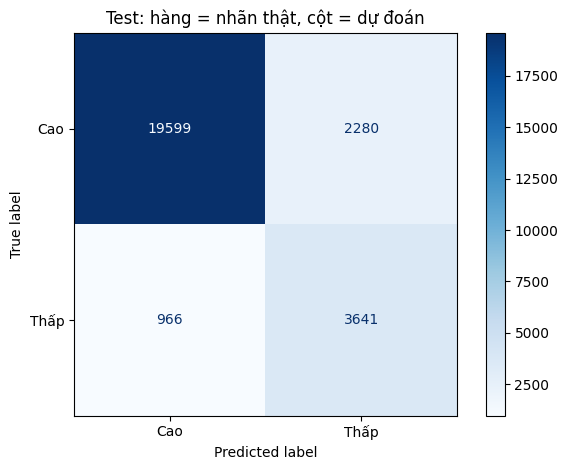

Review test không có feature trong từ vựng: 22


In [8]:
test_pred, test_prob = predict_low(final_model, test['text_norm'])
dummy = DummyClassifier(strategy='prior', random_state=SEED)
dummy.fit(np.zeros((len(reference), 1)), reference['is_low'])
dummy_pred = dummy.predict(np.zeros((len(test), 1)))
dummy_prob = dummy.predict_proba(np.zeros((len(test), 1)))[:, list(dummy.classes_).index(1)]
test_results = pd.DataFrame([
    {'model': 'Dummy: lớp phổ biến', **metric_row(test['is_low'], dummy_pred, dummy_prob)},
    {'model': 'TF-IDF + Logistic Regression', **metric_row(test['is_low'], test_pred, test_prob)},
])
display(test_results.round(4))
print(classification_report(
    test['is_low'], test_pred, labels=[0, 1],
    target_names=['Cao: rating >5', 'Thấp: 0 < rating ≤5'], zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    test['is_low'], test_pred, labels=[0, 1],
    display_labels=['Cao', 'Thấp'], cmap='Blues', values_format='d',
)
plt.title('Test: hàng = nhãn thật, cột = dự đoán')
plt.tight_layout()
plt.show()

X_test_audit = vectorizer.transform(test['text_norm'])
print('Review test không có feature trong từ vựng:', int((X_test_audit.getnnz(axis=1) == 0).sum()))
del X_test_audit


## 9. Tạo bảng trọng số và đối chiếu support/lift

Một dòng tương ứng một feature. `coefficient >0` đẩy log-odds về nhóm thấp; `<0` đẩy về nhóm cao. Độ lớn hệ số chỉ nên so sánh trong cùng mô hình và cách biểu diễn.

- `support_reference`: số review development chứa cụm, mỗi review tối đa 1.
- `low_support_reference`: số review thấp development chứa cụm.
- `p_low_given_term`: tỷ lệ thấp trong các review chứa cụm.
- `lift_reference`: `p_low_given_term / tỷ lệ thấp development`.
- `mean_logit_contribution`: trung bình `w_j × x_j` trên **tất cả** review development, gồm cả giá trị 0.

Lift xét liên hệ riêng của cụm với rating; hệ số được học đồng thời với nhiều feature. Chúng có thể khác hướng vì các n-gram thường chồng lấn hoặc tương quan. Hệ số không chứng minh quan hệ nhân quả. Lift ở đây được tính mới trên development, không phải kết quả kiểm tra ổn định 5 split của notebook EDA.


A. Hệ số dương cao, đủ support; chưa áp điều kiện lift


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
0,tệ,1,13.4538,3089,2135,0.6912,3.9580,0.0295,True
1,làm ăn,2,10.3758,829,574,0.6924,3.9651,0.0070,True
2,lần cuối,2,8.1050,412,317,0.7694,4.4061,0.0025,True
3,dở,1,7.5331,2228,1043,0.4681,2.6808,0.0121,True
4,thái độ,2,7.3648,3817,1985,0.5200,2.9781,0.0170,True
5,kém,1,7.0620,1615,610,0.3777,2.1630,0.0075,True
6,never,1,6.8332,97,80,0.8247,4.7230,0.0007,True
7,bad,1,6.2660,52,32,0.6154,3.5241,0.0004,True
8,dê tươi,2,6.1851,42,24,0.5714,3.2723,0.0006,True
9,tóc,1,6.0045,215,100,0.4651,2.6635,0.0012,True


B. Cùng danh sách A, thêm điều kiện lift ≥ 2.0


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
0,tệ,1,13.4538,3089,2135,0.6912,3.9580,0.0295,True
1,làm ăn,2,10.3758,829,574,0.6924,3.9651,0.0070,True
2,lần cuối,2,8.1050,412,317,0.7694,4.4061,0.0025,True
3,dở,1,7.5331,2228,1043,0.4681,2.6808,0.0121,True
4,thái độ,2,7.3648,3817,1985,0.5200,2.9781,0.0170,True
5,kém,1,7.0620,1615,610,0.3777,2.1630,0.0075,True
6,never,1,6.8332,97,80,0.8247,4.7230,0.0007,True
7,bad,1,6.2660,52,32,0.6154,3.5241,0.0004,True
8,dê tươi,2,6.1851,42,24,0.5714,3.2723,0.0006,True
9,tóc,1,6.0045,215,100,0.4651,2.6635,0.0012,True


C. Feature hướng về nhóm điểm cao — để đối chiếu


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
99999,hơi,1,-10.9894,28990,1673,0.0577,0.3305,-0.1140,True
99998,không bị,2,-8.5712,3627,83,0.0229,0.1310,-0.0161,True
99997,không quá,2,-7.7348,3307,101,0.0305,0.1749,-0.0136,True
99996,thích,1,-7.7258,23914,1164,0.0487,0.2787,-0.0682,True
99995,rộng,1,-7.5137,10006,266,0.0266,0.1522,-0.0300,True
99994,thì phải,2,-7.1480,2624,238,0.0907,0.5194,-0.0094,True
99993,vẫn,1,-7.1248,15534,1791,0.1153,0.6603,-0.0448,True
99992,ko bị,2,-7.0532,1144,36,0.0315,0.1802,-0.0057,True
99991,ổn,1,-6.8423,9876,657,0.0665,0.3810,-0.0308,True
99990,nhanh,1,-6.5836,14978,676,0.0451,0.2585,-0.0376,True


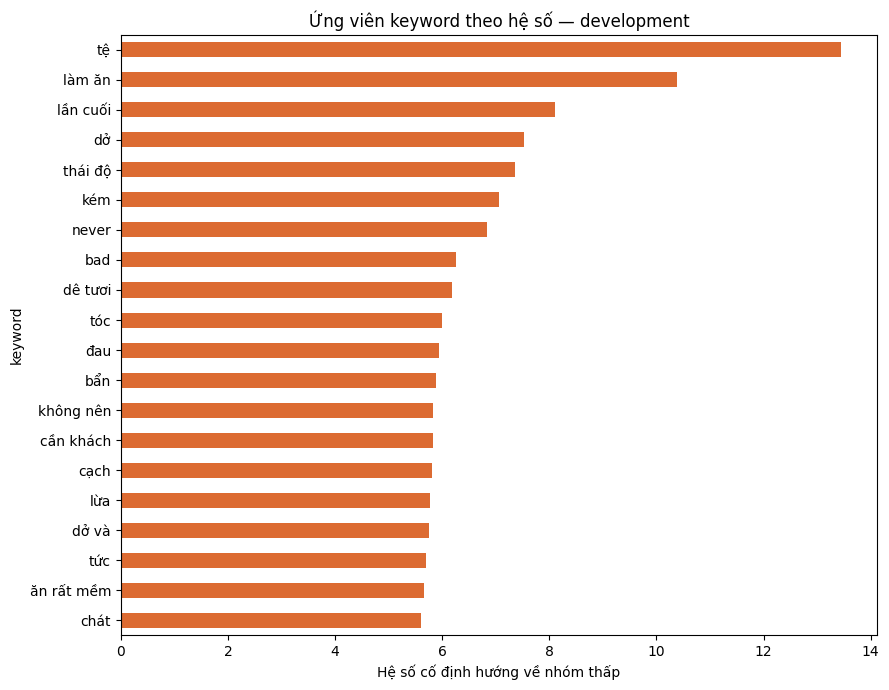

In [9]:
support = np.asarray((X_reference > 0).sum(axis=0)).ravel().astype(np.int64)
low_mask = reference['is_low'].to_numpy(dtype=bool)
low_support = np.asarray((X_reference[low_mask] > 0).sum(axis=0)).ravel().astype(np.int64)
baseline_reference = float(reference['is_low'].mean())
p_low_given_term = np.divide(
    low_support, support, out=np.full(len(support), np.nan), where=support > 0,
)
feature_table = pd.DataFrame({
    'keyword': feature_names,
    'n_tokens': [len(term.split()) for term in feature_names],
    'coefficient': coefficients,
    'support_reference': support,
    'low_support_reference': low_support,
    'p_low_given_term': p_low_given_term,
    'lift_reference': p_low_given_term / baseline_reference,
    'mean_logit_contribution': coefficients * np.asarray(X_reference.mean(axis=0)).ravel(),
})
feature_table['meets_support'] = (
    feature_table['support_reference'].ge(MIN_TOTAL_SUPPORT)
    & feature_table['low_support_reference'].ge(MIN_LOW_SUPPORT)
)
feature_table = feature_table.sort_values('coefficient', ascending=False).reset_index(drop=True)
keyword_candidates = feature_table.loc[
    feature_table['coefficient'].gt(0) & feature_table['meets_support']
].copy()
keyword_with_lift = keyword_candidates.loc[
    keyword_candidates['lift_reference'].ge(MIN_DISPLAY_LIFT)
].copy()

print('A. Hệ số dương cao, đủ support; chưa áp điều kiện lift')
display(keyword_candidates.head(TOP_N).round(4))
print('B. Cùng danh sách A, thêm điều kiện lift ≥', MIN_DISPLAY_LIFT)
display(keyword_with_lift.head(TOP_N).round(4))
print('C. Feature hướng về nhóm điểm cao — để đối chiếu')
display(feature_table.loc[
    feature_table['coefficient'].lt(0)
    & feature_table['support_reference'].ge(MIN_TOTAL_SUPPORT)
].sort_values('coefficient').head(15).round(4))
if keyword_candidates.empty:
    print('Không có ứng viên đạt ngưỡng support. Xem feature_table; chưa đủ bằng chứng ở ngưỡng hiện tại.')

plot_terms = keyword_candidates.head(20).sort_values('coefficient')
if not plot_terms.empty:
    plot_terms.plot.barh(x='keyword', y='coefficient', figsize=(9, 7), legend=False, color='#dc6b32')
    plt.xlabel('Hệ số cố định hướng về nhóm thấp')
    plt.title('Ứng viên keyword theo hệ số — development')
    plt.tight_layout()
    plt.show()


## 10. Đọc ngữ cảnh thật của từng keyword

Dùng chính analyzer/từ vựng của TF-IDF để tìm review chứa feature; tránh tìm chuỗi con sai ranh giới token. Lấy mẫu ở cả nhóm thấp và cao. Đồng thời đếm số nội dung khác nhau và số quán đóng góp để phát hiện cụm chủ yếu xuất hiện nhờ một câu lặp hoặc một quán.

Một cụm trọng số lớn có thể là tên quán, địa danh hoặc mảnh câu thiếu nghĩa. Cần đọc trước khi gọi nó là “keyword diễn đạt sự không hài lòng”. Không tự động suy ra ngữ nghĩa từ dấu hệ số.


In [10]:
def keyword_context(term, n=CONTEXT_SAMPLE_SIZE):
    term = normalize_text(term)
    feature_id = vectorizer.vocabulary_.get(term)
    if feature_id is None:
        print(f'{term!r} không có feature trong từ vựng cuối.')
        return pd.DataFrame()
    hit_positions = X_reference[:, feature_id].nonzero()[0]
    rows = reference.iloc[hit_positions].copy()
    print('Keyword:', term)
    print('Hệ số:', float(coefficients[feature_id]))
    print('Số review:', len(rows), '| Số nội dung:', rows['text_norm'].nunique(),
          '| Số quán:', rows['shop_id'].nunique())
    if not rows.empty:
        concentration = rows['text_norm'].value_counts(normalize=True).iloc[0]
        print(f'Tỷ trọng review từ một nội dung phổ biến nhất: {concentration:.1%}')
    selected = []
    for label in (1, 0):
        group = rows.loc[rows['is_low'].eq(label)]
        if not group.empty:
            selected.append(group.sample(min(n, len(group)), random_state=SEED))
    if not selected:
        return pd.DataFrame()
    result = pd.concat(selected)[['_source_row', 'shop_id', 'rating_num', 'is_low', 'comment_text']]
    with pd.option_context('display.max_colwidth', None):
        display(result)
    return result

# Có thể thay bằng một keyword cụ thể: keyword_context('phục vụ chậm').
if not keyword_candidates.empty:
    context_example = keyword_context(keyword_candidates.iloc[0]['keyword'])


Keyword: tệ
Hệ số: 13.453847351681413
Số review: 3089 | Số nội dung: 3055 | Số quán: 1118
Tỷ trọng review từ một nội dung phổ biến nhất: 0.4%


,_source_row,shop_id,rating_num,is_low,comment_text
79647,79911,com-tam-bui-sai-gon,2.4,1,"Lâu ngày thèm ăn cơm sườn non nên sáng nay ghé quán, thất vọng vô cùng khi bưng ra dĩa cơm hai cục sườn non nhỏ xiu vậy mà tổng hết 43k. Càng ngày càng dở tệ mà mắc nữa, bạn nào không tin có thể tới thử độ chặt chém của quán. Mình không bao giờ quay lại chào thân ái"
26409,26553,banh-bao-hu-tieu-ca-can,4.6,1,"Cả cần là thương hiệu rất nổi tiếng từ khi mình còn bé xíu. Hôm qua trong nhà có tiệc nên mua 4cái đbiệt về, giá 38k/cái.\nLúc vừa xé bánh ra thì mình thấy mùi thơm. Nhưng ăn chưa được 5s thì lại bị chính mùi thơm đó làm khó chịu.\nNhân bánh gồm thịt heo, tôm khô lớn, trứng muối, nấm đông cô, bún tàu. Tất cả trộn lại 1mùi rất tanh và khó chịu. Vỏ bánh cũng không có gì đặc sắc, chỗ thì bở, chỗ thì rỗng, rất tệ!\nTóm lại, giá quá chát cho 1cái bánh mà chất lượng thì tệ không thể nói."
115846,117371,banh-trang-cuon-thit-heo-hoang-beo-nguyen-ngoc-vu,1.0,1,"Hnay mình có đến đây ăn lần đầu tiên và cũng là lần cuối cùng. Lúc mình đến thì quán chưa có khách, thấy cũng khá vắng vẻ nhưng chỉ nghĩ là sớm chưa đến h. . Bọn mình gọi đồ xong sau đó k thấy có nv đứng để ý khách xem thiếu j thì gọi thêm, hết rau hết nc chấm thì tự lấy thêm. Cái này cũng k quan trọng lắm vì thôi cái j làm được thì mình tự làm. Sau đó mấy chị e có ngồi nói chuyện thì cũng nói to. Vì lúc bọn mình đến quán không hề có khách, và bọn mình ngồi tầng 2 sau đó đến tận lúc về cũng k có ai. Đùng cái chủ quán hay quản lí lên quát vào mặt bọn kiểu rất khó chịu làm mình giật mình “Nói bé bé thôi có ý thức xem nào, có 3 đứa con gái mà ầm ầm cả tầng 1”. Lúc đấy mình thật sự rất shock. Vì thứ nhất mình cũng từng làm nhà hàng r, th kh nc to làm ảnh hưởng xung quanh thì phải nhắc nhở trc, nếu cố tình tiếp thì có thể tỏ thái độ. Trong khi trc đấy k hề có ai lên tiếng nhắc bọn mình, mà lên chửi thẳng mặt luôn. Đồ ăn ở đây cũng k tính là quá đặc sắc so với những chỗ khác, nhưng thái độ của nv ở đây thì quá tệ tệ tệ. Quán k hề đông khách, có đến 3 4 nhân viên thì một câu nhắc nhở có thật sự khó khăn đến vậy. Chúng mình có lỗi khi nc to, nhưng chỉ là vô ý chứ k vô ý thức, cảm thấy vui vẻ nếu được nhắc nhở CHỨ KHÔNG PHẢI CHỬI VÀO MẶT NHƯ THẾ."
29744,29893,banh-bo-thot-not-nguyen-son-le-tu-tai,5.0,1,Lúc ăn ngon lúc dở nhưng mà thái độ chủ quán tệ quá
120905,122516,hieu-banh-dong-phuong-cau-dat,3.4,1,"Nổi tiếng là chuyện ngày xưa. Bây giờ k hiểu cảm giác ẩm thực của người ăn thế nào chứ mình thì thấy bình thường, thậm chí là còn kém. Thái độ phục vụ thì khá tệ. Trước còn hay mua chứ bh nhiều khi đc biếu nhưng chả thèm ăn."
31002,31157,ga-ran-burger-mcdonald-s-da-kao,7.2,0,"👉👉 Chỉ áp dụng tặng ly khi sử dụng voucher đang khuyến mãi trên HotDeal á. Giảm giá Combo đến tận 50% từ 178k -> còn 89k á - Áp dụng voucher từ 25/11 -> 20/12, trong khung giờ 11 giờ trưa đến 4 giờ sáng 😁\n💓Combo gồm: 2ly nước ngọt size vừa, 2 phần khoai tây chiên size vừa, 6 miếng McNuggets, 1 CheeseBurger Deluxe và tặng kèm 1 ly Cocacola miễn phí (có kèm hình bên dưới).\n👉Mình thấy áp dụng luôn cả chi nhánh Mac ở sân bay luôn á, nhưng mình tiện đường nên đi bên Điện Biên Phủ ^^\n\n* Vị trí: chi nhánh Mac đầu tiên ở sì gòn nên chắc ai cũng biết đến ẻm hỉ, ngay bùng binh luôn\n* Không gian: có 2 lựa chọn ngồi ngoài trời hoặc phía trong máy lạnh, và có 1 lầu nữa, bước vào đập vào mắt là khu order nhìn khá hoành tráng, order xong qua quầy kế bên đợi tới số lấy food nhá 😄 Lúc mình đi mưa tầm tã nên không ngồi phía ngoài được, bên ngoài thấy khá thoáng mát, và ngắm đc xe cộ. Hỡm có tới mấy cái sinh nhật cho con nít ở trên lầu nên khá ồn ào, nhìn từ phía ngoài tưởng vắng ai dè dô trong cũng đông khách lắm. 😅\n\n❌ Nhân viên: mặt mày một vài nhân viên chưa được thân thiện tươi cười niềm nở với khách cho lắm. Lúc mình order hỏi có menu giấy không cho mình xin thì bảo không có, lúc sau thì có 1 nv tên ""Thao Ho"" phục vụ rất dễ thương và chu đáo, mình không xin chỉ nhưng lúc mình chụp hình bị chói không thấy được menu nên có khíu c

## 11. Giải thích một review bằng TF-IDF × trọng số

`explain_review()` trả về từng feature **thực sự xuất hiện trong vector** cùng `tfidf`, `coefficient` và `contribution`. Cột `coefficient` cố định cho mọi câu, còn TF-IDF và đóng góp thay đổi theo câu.

Hàm kiểm tra `bias + tổng contribution = decision_function` của mô hình. Các bảng top dương/âm chỉ là phần hiển thị; tổng kiểm tra luôn dùng toàn bộ feature hoạt động. Đóng góp đo trên thang logit, không phải số điểm phần trăm xác suất, và không trực tiếp so với nhau như xác suất độc lập.

N-gram chồng lấn cùng đóng góp: “phục”, “vụ”, “chậm”, “phục vụ”, “vụ chậm”, “phục vụ chậm” có thể cùng xuất hiện nếu có trong từ vựng. Không gộp chúng tùy ý rồi coi đó là đóng góp duy nhất của cả cụm. Nếu toàn bộ token nằm ngoài từ vựng, dự đoán chỉ dựa vào bias.


In [11]:
def explain_review(text, top_k=10, show=True):
    text_norm = normalize_text(text)
    x = vectorizer.transform([text_norm]).tocsr()
    ids = x.indices
    values = x.data
    contributions = values * coefficients[ids]
    explanation = pd.DataFrame({
        'feature': feature_names[ids], 'tfidf': values,
        'coefficient': coefficients[ids], 'contribution': contributions,
    }).sort_values('contribution', ascending=False).reset_index(drop=True)
    logit = float(final_model.decision_function([text_norm])[0])
    probability = float(final_model.predict_proba([text_norm])[0, 1])
    reconstructed_logit = bias + float(contributions.sum())
    assert np.isclose(reconstructed_logit, logit, atol=1e-8)
    assert np.isclose(expit(logit), probability, atol=1e-8)
    summary = {
        'text_norm': text_norm,
        'active_features': int(x.nnz),
        'bias': bias,
        'sum_contributions': float(contributions.sum()),
        'logit': logit,
        'p_low_model': probability,
        'predicted_is_low': int(probability >= PREDICTION_THRESHOLD),
    }
    if show:
        print('Review:', text)
        display(pd.Series(summary, name='Giá trị').to_frame())
        if explanation.empty:
            print('Không có feature hoạt động. Mô hình chỉ sử dụng bias.')
        else:
            print('Feature đẩy về nhóm thấp:')
            display(explanation.loc[explanation['contribution'].gt(0)].head(top_k).round(6))
            print('Feature đẩy về nhóm cao:')
            display(explanation.loc[explanation['contribution'].lt(0)].tail(top_k).sort_values('contribution').round(6))
            print('Tổng đóng góp đã kiểm tra với decision_function của mô hình.')
    return summary, explanation

CUSTOM_REVIEW = 'Đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu.'
custom_summary, custom_explanation = explain_review(CUSTOM_REVIEW)


Review: Đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu.


,Giá trị
text_norm,"đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu."
active_features,25
bias,0.887019
sum_contributions,-0.341126
logit,0.545893
p_low_model,0.633182
predicted_is_low,1


Feature đẩy về nhóm thấp:


,feature,tfidf,coefficient,contribution
0,chậm,0.191089,2.874862,0.549354
1,đợi,0.146472,2.979862,0.436466
2,phục vụ chậm,0.263080,1.375211,0.361791
3,vụ chậm,0.262413,1.059193,0.277946
4,rất lâu,0.229838,1.206290,0.277251
5,vụ,0.093659,1.712174,0.160361
6,đồ,0.095167,1.529233,0.145532
7,ngon nhưng phục,0.344516,0.285865,0.098485
8,đồ ăn,0.110255,0.853226,0.094073
9,ăn ngon,0.136822,0.146445,0.020037


Feature đẩy về nhóm cao:


,feature,tfidf,coefficient,contribution
24,ngon nhưng,0.167903,-3.208495,-0.538716
23,ăn ngon nhưng,0.259856,-1.481641,-0.385013
22,đợi rất lâu,0.299162,-1.139326,-0.340843
21,lâu,0.113666,-1.841435,-0.209308
20,ăn,0.051538,-3.883397,-0.200142
19,đợi rất,0.292767,-0.656516,-0.192207
18,nhưng phục,0.226460,-0.779221,-0.176463
17,nhưng,0.073281,-2.282244,-0.167246
16,nhưng phục vụ,0.226614,-0.729262,-0.165261
15,chậm đợi,0.358220,-0.357068,-0.127909


Tổng đóng góp đã kiểm tra với decision_function của mô hình.


## 12. Thử phủ định và xem giới hạn ngữ cảnh

Các câu sau chỉ là ví dụ chẩn đoán, không có nhãn rating và không tham gia fit hay báo cáo điểm test. Chạy để quan sát thay vì áp sẵn kết luận. N-gram có thể biểu diễn một số phủ định gần, nhưng mô hình tuyến tính không bảo đảm hiểu phủ định dài, nhiều khía cạnh hoặc mỉa mai.

Do chuẩn hóa L2, thêm một từ còn có thể thay đổi TF-IDF của những từ đã có. Vì vậy chênh lệch xác suất giữa hai câu không chỉ do một hệ số mới. Tìm keyword bằng hệ số vẫn cần đánh giá ngữ cảnh thủ công.


In [12]:
diagnostic_texts = [
    'Nhân viên thiếu tôn trọng khách.',
    'Không hề có chuyện nhân viên thiếu tôn trọng khách.',
    'Đồ ăn ngon nhưng nhân viên thiếu tôn trọng khách.',
    'Phục vụ chậm.',
    'Phục vụ không chậm.',
]
diagnostic_rows = []
for text in diagnostic_texts:
    summary, _ = explain_review(text, show=False)
    diagnostic_rows.append({'review': text, **summary})
display(pd.DataFrame(diagnostic_rows)[['review', 'active_features', 'p_low_model', 'predicted_is_low']])

# Bỏ dấu # nếu muốn xem đầy đủ đóng góp của câu phủ định.
# explain_review(diagnostic_texts[1])


,review,active_features,p_low_model,predicted_is_low
0,Nhân viên thiếu tôn trọng khách.,14,0.789811,1
1,Không hề có chuyện nhân viên thiếu tôn trọng k...,22,0.815413,1
2,Đồ ăn ngon nhưng nhân viên thiếu tôn trọng khách.,26,0.713475,1
3,Phục vụ chậm.,6,0.973265,1
4,Phục vụ không chậm.,7,0.990748,1


## 13. Đọc lỗi phân loại sau khi chốt mô hình

Lấy các dự đoán sai có độ tự tin cao để tìm giả thuyết lỗi: rating lệch nội dung, khen/chê lẫn nhau, từ ngoài từ vựng, phủ định hoặc tên quán. Các mẫu tự tin cao không đại diện cho toàn bộ lỗi. Có thể gọi `explain_review()` với một review sai để xem mô hình dựa vào feature nào.

Đây là phân tích test sau đánh giá, không dùng để chỉnh mô hình rồi báo lại cùng test như kết quả độc lập.


In [13]:
test_predictions = test[['_source_row', 'shop_id', 'rating_num', 'comment_text', 'text_norm', 'is_low']].copy()
test_predictions['predicted_is_low'] = test_pred
test_predictions['p_low_model'] = test_prob
test_predictions['correct'] = test_predictions['is_low'].eq(test_pred)
test_predictions['confidence_predicted_class'] = np.where(test_pred == 1, test_prob, 1 - test_prob)
errors = test_predictions.loc[~test_predictions['correct']].sort_values(
    'confidence_predicted_class', ascending=False,
)
with pd.option_context('display.max_colwidth', 180):
    display(errors.head(15))
if not errors.empty:
    error_summary, error_explanation = explain_review(errors.iloc[0]['comment_text'])
else:
    print('Không có lỗi trong tập test hiện tại; vẫn cần kiểm tra tính đại diện và rò rỉ dữ liệu.')


,_source_row,shop_id,rating_num,comment_text,text_norm,is_low,predicted_is_low,p_low_model,correct,confidence_predicted_class
130337,131999,butterfly-tea-bai-chay,4.8,Về Hạ Long được con bạn đưa đi uống. Về vị trí thì khá là dễ tìm. Không gian tuy không rộng lắm nhưng vẫn có nhiều chỗ để sống ảo 😂😂. Vị trà sữa thì đối với mình là vừa nhưng v...,về hạ long được con bạn đưa đi uống. về vị trí thì khá là dễ tìm. không gian tuy không rộng lắm nhưng vẫn có nhiều chỗ để sống ảo 😂😂. vị trà sữa thì đối với mình là vừa nhưng v...,1,0,0.000266,False,0.999734
111963,113487,banh-ga-than-thanh-158-hong-mai,3.4,"Thấy lạ nên ghé qua ăn thử ai dè ngon không tưởng.Hai đứa con mình thích mê tơi luôn, giá rất rẻ, vị lạ. Quán nhỏ nhưng sạch sẽ, chủ quán niềm nở, nhiệt tình. Tìm quán hơi khó ...","thấy lạ nên ghé qua ăn thử ai dè ngon không tưởng.hai đứa con mình thích mê tơi luôn, giá rất rẻ, vị lạ. quán nhỏ nhưng sạch sẽ, chủ quán niềm nở, nhiệt tình. tìm quán hơi khó ...",1,0,0.000476,False,0.999524
9676,9711,mi-kim-chi-omega-ly-tu-trong,10.0,Not bad,not bad,0,1,0.999396,False,0.999396
4487,4503,sai-gon-bakery,5.0,"Sài Gòn Bakery \nMình rất thích bánh muffin ở đây, hôm nay ăn muffin trà xanh, mùi trà xanh thơm nức mũi, rất thích luôn. \nBánh mì bi thì hơi khô nhưng ăn nhâm nhi cũng được\n...","sài gòn bakery mình rất thích bánh muffin ở đây, hôm nay ăn muffin trà xanh, mùi trà xanh thơm nức mũi, rất thích luôn. bánh mì bi thì hơi khô nhưng ăn nhâm nhi cũng được theo ...",1,0,0.000725,False,0.999275
88980,89251,starbucks-coffee-297589,5.8,"Ngày 5/2/2018 tôi Có order 1 cafe Latte size lớn, giá ghi trên bảng là 78.000 vnd, đến khi tính tiền lại là 86.000, hỏi lại e phục vụ thì e nói giá bán đã thay đổi mà bên cửa h...","ngày 5/2/2018 tôi có order 1 cafe latte size lớn, giá ghi trên bảng là 78.000 vnd, đến khi tính tiền lại là 86.000, hỏi lại e phục vụ thì e nói giá bán đã thay đổi mà bên cửa h...",0,1,0.999032,False,0.999032
120091,121702,mr-good-tea-lach-tray,5.0,"Trà sữa Mr. Good Tea rất đáng để mn mua dùng thường xuyên, chất lượng rất tốt giá cả vừa phải nên quán rất đông sinh viên và học sinh, giờ tan học thì đông lắm luôn, nên nếu mu...","trà sữa mr. good tea rất đáng để mn mua dùng thường xuyên, chất lượng rất tốt giá cả vừa phải nên quán rất đông sinh viên và học sinh, giờ tan học thì đông lắm luôn, nên nếu mu...",1,0,0.000980,False,0.999020
25291,25431,tra-sua-gong-cha-phan-xich-long,4.4,Bánh bèo thích trà sữa lần đầu uống Gong Cha- một thương hiệu nổi tiếng. Mình thấy uống thì ngon nhưng cũng không quá xuất sắc.\n2 chị em cùng sở thích socola nên chị mình uống...,bánh bèo thích trà sữa lần đầu uống gong cha- một thương hiệu nổi tiếng. mình thấy uống thì ngon nhưng cũng không quá xuất sắc. 2 chị em cùng sở thích socola nên chị mình uống ...,1,0,0.001053,False,0.998947
71426,71682,hanuri-quan-an-han-quoc,6.0,"Quán hẹp, phục vụ rất tệ mình muốn xin đôi đũa đợi cả tiếng không thấy đâu, nguời khác vô sau xin đôi đũa chưa đến 5 phút là có liền, mình vô để đồ giữ chỗ ra kêu món thì tự t...","quán hẹp, phục vụ rất tệ mình muốn xin đôi đũa đợi cả tiếng không thấy đâu, nguời khác vô sau xin đôi đũa chưa đến 5 phút là có liền, mình vô để đồ giữ chỗ ra kêu món thì tự ti...",0,1,0.998798,False,0.998798
2344,2353,1985-coffee-com-que-com-tam-long-xuyen-ly-tu-trong,4.6,"Ghé quán vào buổi sáng thử. Lần đầu tiên đi hết không gian của 1985 cảm thấy không gian ở đây ấm cúng, có thể chụp hình so deep được. Với ngồi ngắm view trên cao thấy hồ sáng...","ghé quán vào buổi sáng thử. lần đầu tiên đi hết không gian của 1985 cảm thấy không gian ở đây ấm cúng, có thể chụp hình so deep được. với ngồi ngắm view trên cao thấy hồ sáng t...",1,0,0.001333,False,0.998667
82011,82276,ga-ran-va-mi-y-jollibee-bigc-an-lac,5.6,"Mình xếp hàng đã đời, xong đến lượt mình thì tính cho người khác, trong khi khách hàng đó không xếp hàng, còn đến sau mình, mình hỏi thì bảo mình đợi xíu, ngộ ghê, vậy sau này ...","mình xếp hàng đã đời, xong đến lượt mình thì tính cho người khác, trong k

Review: Về Hạ Long được con bạn đưa đi uống. Về vị trí thì khá là dễ tìm. Không gian tuy không rộng lắm nhưng vẫn có nhiều chỗ để sống ảo 😂😂. Vị trà sữa thì đối với mình là vừa nhưng với khẩu vị nhìu ng mình nghĩ là hơi nhạt. Vì là tín đồ của matcha nên đa phần là mình uống matcha. Pudding ở đây khá đa dạng mình thích nhất là hạt thuỷ tinh và lô hội. Hạt thuỷ tinh sẽ hơi chua còn lô hội thì hơi ngọt. Nhân viên ở đây rất thân thiện. Mình nghĩ đây là 1 quán khá ổn vì giá cả phù hợp với học sinh sinh viên mà lại đa dạng đồ uống. Tuy nhiên điểm trừ là kem sữa ở đây hơi mặn.
Quán đang có combo bánh trứng gà non kèm trà sữa 35k mà hnay ra thì hết mất r. Bánh rất ngon và thơm. Tuy nhiên giá khá cao 20-25k 1 chiếc. 
Quán có thẻ tích điểm nên cứ uống thoải mái r 1 ngày đẹp zời bạn sẽ đc tặng free 1 cốc 😂😂


,Giá trị
text_norm,về hạ long được con bạn đưa đi uống. về vị trí...
active_features,347
bias,0.887019
sum_contributions,-9.118328
logit,-8.231309
p_low_model,0.000266
predicted_is_low,0


Feature đẩy về nhóm thấp:


,feature,tfidf,coefficient,contribution
0,hnay,0.048525,4.223919,0.204966
1,ngon và thơm,0.057817,3.379071,0.195366
2,r,0.077800,2.494021,0.194034
3,về vị trí,0.061266,3.042841,0.186424
4,nghĩ,0.066007,2.671287,0.176323
5,thì,0.054911,3.158196,0.173419
6,quán khá ổn,0.067652,2.410698,0.163088
7,1,0.068765,2.325772,0.159933
8,ở đây khá,0.041287,3.633915,0.150033
9,đây hơi,0.051521,2.887775,0.148782


Feature đẩy về nhóm cao:


,feature,tfidf,coefficient,contribution
346,hơi,0.071115,-10.989426,-0.781517
345,khá,0.069344,-5.449198,-0.377868
344,uống,0.091290,-4.016412,-0.366658
343,tuy,0.087396,-3.811134,-0.333080
342,matcha,0.082652,-3.236612,-0.267512
341,đây,0.062540,-4.167426,-0.260629
340,là,0.100618,-1.996174,-0.200851
339,free,0.039473,-5.019552,-0.198136
338,rộng,0.026009,-7.513689,-0.195421
337,thuỷ tinh,0.131452,-1.437064,-0.188906


Tổng đóng góp đã kiểm tra với decision_function của mô hình.


## 14. Tạo phiếu đánh giá keyword thủ công

Để đánh giá đúng mục tiêu cuối, lấy mẫu ngữ cảnh từ development cho top keyword và đánh dấu thủ công:

- `is_complaint_in_context`: `1` khi cụm trong ngữ cảnh đang thể hiện ý chê, `0` khi không; bỏ trống nếu chưa gán nhãn.
- `aspect`: ví dụ phục vụ, đồ ăn, giá, vệ sinh hoặc khác.
- `annotation_notes`: phủ định, mỉa mai, mảnh câu, tên riêng, trường hợp mơ hồ.

Rating không tự điền nhãn ngữ nghĩa này. Phiếu có cột nguồn và rating để tiện kiểm tra; khi đánh giá mù, nên ẩn các cột đó trong bản gán nhãn. Đây là mẫu đọc thủ công của **top keyword**, không phải đánh giá chất lượng trích xuất trên mọi review. Tỷ lệ gán nhãn “ý chê” chưa đo recall hoặc phát hiện keyword bị bỏ sót; các dòng cùng review/keyword có thể phụ thuộc nhau.


In [14]:
annotation_rows = []
for term in keyword_candidates.head(TOP_N)['keyword']:
    feature_id = vectorizer.vocabulary_[term]
    positions = X_reference[:, feature_id].nonzero()[0]
    pool = reference.iloc[positions]
    selected = pool.sample(min(CONTEXT_SAMPLE_SIZE, len(pool)), random_state=SEED)
    for _, row in selected.iterrows():
        annotation_rows.append({
            'keyword': term, 'source_row': int(row['_source_row']),
            'shop_id': row['shop_id'], 'rating_num': row['rating_num'],
            'comment_text': row['comment_text'],
            'is_complaint_in_context': '', 'aspect': '', 'annotation_notes': '',
        })
annotation_template = pd.DataFrame(annotation_rows, columns=[
    'keyword', 'source_row', 'shop_id', 'rating_num', 'comment_text',
    'is_complaint_in_context', 'aspect', 'annotation_notes',
])
print('Số dòng cần đọc và gán nhãn:', len(annotation_template))
display(annotation_template.head(10))


Số dòng cần đọc và gán nhãn: 150


,keyword,source_row,shop_id,rating_num,comment_text,is_complaint_in_context,aspect,annotation_notes
0,tệ,109609,banh-trang-tron-tina-tran-33-chua-lang,2.6,bánh trán trộn và cút xào me ăn dở tệ,,,
1,tệ,57607,sumo-bbq-cao-thang-buffet-nuong-lau,5.8,Món ăn:\n- Nhóm mình gọi buffet 249k thì menu ...,,,
2,tệ,67131,lien-hua-hu-tieu-nam-vang-vo-van-tan,1.8,"Vào gọi 3 bát, 2 nước 1 khô thì mang ra 2 bát ...",,,
3,tệ,103819,ga-ran-va-mi-y-jollibee-pham-ngoc-thach,8.0,Thề là Vincom PNT hiu hắt vãi có mỗi Jollibee ...,,,
4,tệ,78994,mi-quang-my-son-dinh-tien-hoang,1.0,"Ngày cuối tuần trời mưa không ngớt, mình ghé v...",,,
5,làm ăn,99695,quan-com-pasteur,1.0,"Không nên ăn nha bà con, 1 đĩa cơm chút xíu đồ...",,,
6,làm ăn,75491,bun-thit-nuong-hai-dang-149-chan-hung-khong-ch...,6.6,Vào đường Chấn Hưng có khá nhiều quán bún thịt...,,,
7,làm ăn,56026,rau-ma-mix-nuoc-ep-tra-trai-cay-269-nguyen-tri...,3.6,Shop làm ăn ngộ nhỉ?Khuyến mãi bán cho mình ly...,,,
8,làm ăn,90479,dy-cake-tiem-banh-bong-lan-trung-muoi-shop-online,1.0,Quá thất vọng. Đúng là ảnh quảng cáo và lúc đặ...,,,
9,làm ăn,32869,com-ga-xoi-mo-142-ba-dinh,3.4,"Cơm thì thiu như để mấy ngày luôn rồi ý, lần đ...",,,


## 15. Lưu kết quả, mô hình và cấu hình

Lưu bundle gồm mô hình cuối và các tham số cần để dùng lại. TF-IDF đã lưu từ vựng/IDF; Logistic Regression đã lưu hệ số/bias. Khi dự đoán mới phải dùng đúng bundle, không fit lại TF-IDF riêng cho câu mới. Chỉ load file joblib từ nguồn tin cậy.

Các CSV tách rõ danh sách feature, ứng viên, bảng thêm điều kiện lift, dự đoán test và phiếu gán nhãn. Thư mục output có timestamp để không ghi đè kết quả lần chạy trước. `split_assignment.csv` và SHA-256 dữ liệu giúp đối chiếu thí nghiệm; version thư viện và seed cũng được lưu.


In [15]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_dir = OUTPUT_DIR / run_stamp
run_dir.mkdir(parents=True, exist_ok=False)
split_assignment = pd.concat([
    part[['_source_row', 'text_norm', 'is_low']].assign(split=name)
    for name, part in parts.items()
]).sort_values('_source_row')
tables = {
    'cleaning_audit.csv': cleaning_audit.rename_axis('item').reset_index(),
    'split_report.csv': split_report,
    'split_assignment.csv': split_assignment,
    'validation_metrics.csv': validation_results,
    'test_metrics.csv': test_results,
    'all_feature_weights.csv': feature_table,
    'keyword_candidates.csv': keyword_candidates,
    'keyword_candidates_lift_ge_2.csv': keyword_with_lift,
    'test_predictions.csv': test_predictions,
    'keyword_annotation_template.csv': annotation_template,
    'custom_review_contributions.csv': custom_explanation,
}
for filename, table in tables.items():
    table.to_csv(run_dir / filename, index=False, encoding='utf-8-sig')

config = {
    'seed': SEED, 'data_path': str(DATA_PATH), 'data_sha256': sha256_file(DATA_PATH),
    'sklearn_version': sklearn.__version__, 'numpy_version': np.__version__,
    'pandas_version': pd.__version__, 'low_rating_threshold': LOW_RATING_THRESHOLD,
    'max_rating': MAX_RATING, 'dedup_fields': [
        'source_platform', 'shop_id', 'comment_datetime', 'device', 'rating_num', 'text_norm',
    ],
    'token_pattern': TOKEN_PATTERN, 'ngram_range': NGRAM_RANGE,
    'min_df': MIN_DF, 'max_features': MAX_FEATURES, 'class_weight': CLASS_WEIGHT,
    'C_values': C_VALUES, 'selected_C': best_c, 'max_iter': MAX_ITER,
    'prediction_threshold': PREDICTION_THRESHOLD,
    'test_group_size': TEST_GROUP_SIZE,
    'valid_group_size_of_remainder': VALID_GROUP_SIZE_OF_REMAINDER,
    'min_total_support': MIN_TOTAL_SUPPORT, 'min_low_support': MIN_LOW_SUPPORT,
    'min_display_lift': MIN_DISPLAY_LIFT,
    'n_features': len(feature_names), 'keyword_reference': 'train_plus_validation_only',
    'created_at_utc': run_stamp,
}
with (run_dir / 'experiment_config.json').open('w', encoding='utf-8') as stream:
    json.dump(config, stream, ensure_ascii=False, indent=2)
joblib.dump({'pipeline': final_model, 'config': config}, run_dir / 'logistic_keywords.joblib')
print('Đã lưu kết quả vào:', run_dir.resolve())
display(pd.DataFrame({'file': sorted(path.name for path in run_dir.iterdir())}))


Đã lưu kết quả vào: D:\FPT\ADY291m\project\notebooks\outputs\logistic_keywords\20261113T145627_018248Z


,file
0,all_feature_weights.csv
1,cleaning_audit.csv
2,custom_review_contributions.csv
3,experiment_config.json
4,keyword_annotation_template.csv
5,keyword_candidates.csv
6,keyword_candidates_lift_ge_2.csv
7,logistic_keywords.joblib
8,split_assignment.csv
9,split_report.csv


## 16. Cách đọc và trình bày kết quả

Sau khi chạy dữ liệu thật, điền nhận xét dựa trên output:

1. **Dữ liệu:** số review sau lọc, tỷ lệ điểm thấp, quy mô và tỷ lệ lớp từng tập có chênh lệch đáng kể không?
2. **Khả năng dự đoán:** macro-F1 so với Dummy; precision/recall nhóm thấp cho thấy bỏ sót hay báo nhầm nhiều hơn? Đọc confusion matrix.
3. **Keyword toàn cục:** cụm hệ số dương lớn có đủ support không, có phải mảnh câu/tên riêng không? Điều kiện lift làm danh sách thay đổi thế nào?
4. **Keyword theo review:** lấy một câu, chỉ rõ TF-IDF, hệ số cố định, tích của chúng và ảnh hưởng đến logit. Feature vắng mặt không đóng góp.
5. **Ngữ cảnh:** kiểm tra phủ định và review sai. Không kết luận “hiểu ngữ cảnh” chỉ từ điểm phân loại cao.
6. **Chất lượng đầu ra:** báo cáo riêng kết quả gán nhãn thủ công keyword; chưa có nhãn thì chỉ gọi là ứng viên.

**Giới hạn cần giữ khi kết luận:** nhãn rating là nhãn thay thế cho cảm xúc; hệ số phụ thuộc từ vựng, regularization và các feature tương quan. Lần chạy này chưa đo ổn định hệ số qua nhiều lần chia. Bảng lift development chưa lặp lại discovery/validation 5 lần như EDA. Đánh giá test hiện tại đo review có nội dung mới theo `text_norm`, chưa kiểm chứng quán mới, thời điểm mới hoặc câu diễn đạt gần giống.

Không đặt sẵn kết luận về keyword tốt nhất hoặc mô hình tốt đến đâu trước khi có output thực tế.
